# SAM 3 / SAM 3.1 room upgrade
Completed GPU experiments, gated object fusion and short temporal-mask motion checks. This notebook reviews cached results; see `research/SAM_UPGRADE_REPORT.md` for limitations and timing scope.

Recompute GPU stages separately with `.venv-sam31/Scripts/python.exe research/try_sam.py image`, `hybrid`, `video`, `video --prompt beanbag`. CPU fusion uses the original Anaconda runtime. The complete room identity map does not yet use SAM 3.1 tracks.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
assert (ROOT/'research').exists()
sys.path.insert(0,str(ROOT/'.packages'))
import numpy as np,pandas as pd
from IPython.display import display,Image,HTML
summary=json.loads((ROOT/'outputs/sam_trial/sam_summary.json').read_text())
display(summary)
assert summary['fusion']['accepted_refinements']+summary['fusion']['fallbacks']==summary['fusion']['proposals']

{'fusion': {'proposals': 243,
  'sam_masks': 243,
  'accepted_refinements': 186,
  'fallbacks': 57,
  'objects': 9,
  'classes': ['air vent',
   'armchair',
   'beanbag',
   'door',
   'picture',
   'sofa',
   'storage table',
   'window',
   'window'],
  'geometry': 'Existing measured mesh and room alignment; object masks refined only',
  'limitations': 'Geometry gates are consistency proxies, not annotated mask accuracy. Same-room visual references and inferred depth scale remain.'},
 'tracking': {'furniture': {'frames_with_masks': 90,
   'unique_ids': [0],
   'observations': 90},
  'beanbag': {'frames_with_masks': 90, 'unique_ids': [0], 'observations': 90}},
 'motion_valid_pixels': {'box': 7529,
  'sam31_tracking': 9322,
  'sam3_refinement': 8917},
 'tracked_mask_pixel_gain_percent': 23.814583610041183,
 'motion_pairs': [400, 450],
 'claim': 'Consistency and qualitative evidence; no ground-truth accuracy benchmark'}

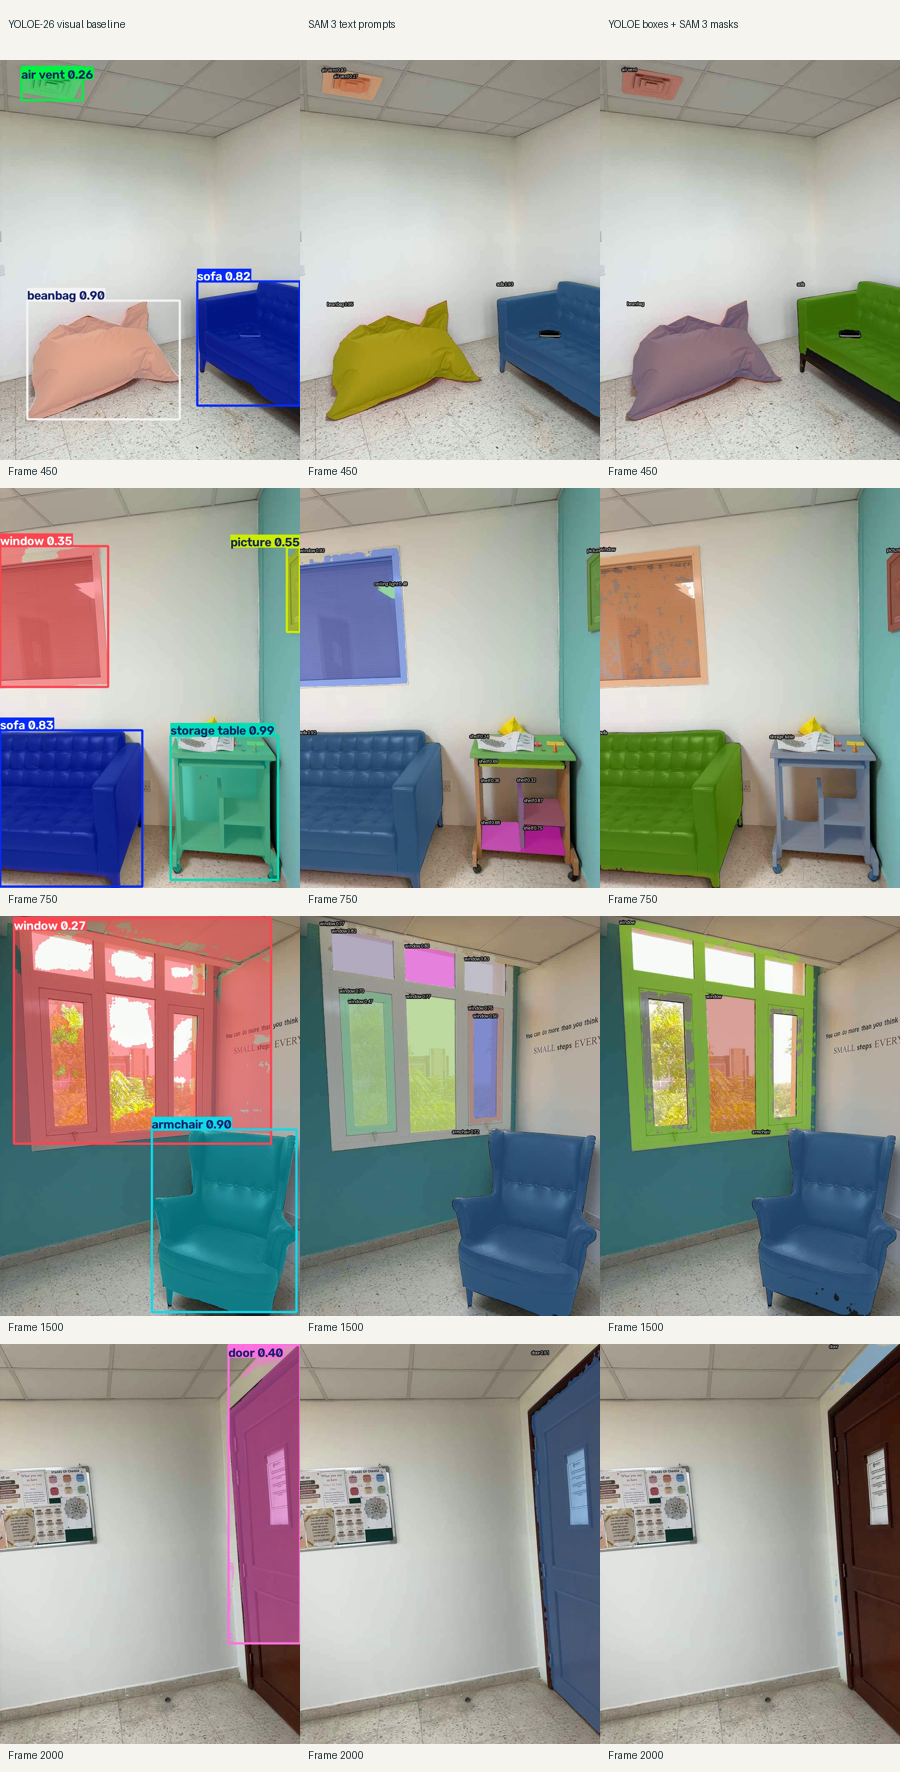

Compare masks and failures; detection count is not accuracy.


In [2]:
display(Image(filename=str(ROOT/'outputs/sam_trial/sam_comparison.png')))
print('Compare masks and failures; detection count is not accuracy.')

,frames,minimum_mask_pixels
object_id,,
0,90,34456


,frames,minimum_mask_pixels
object_id,,
0,90,51429


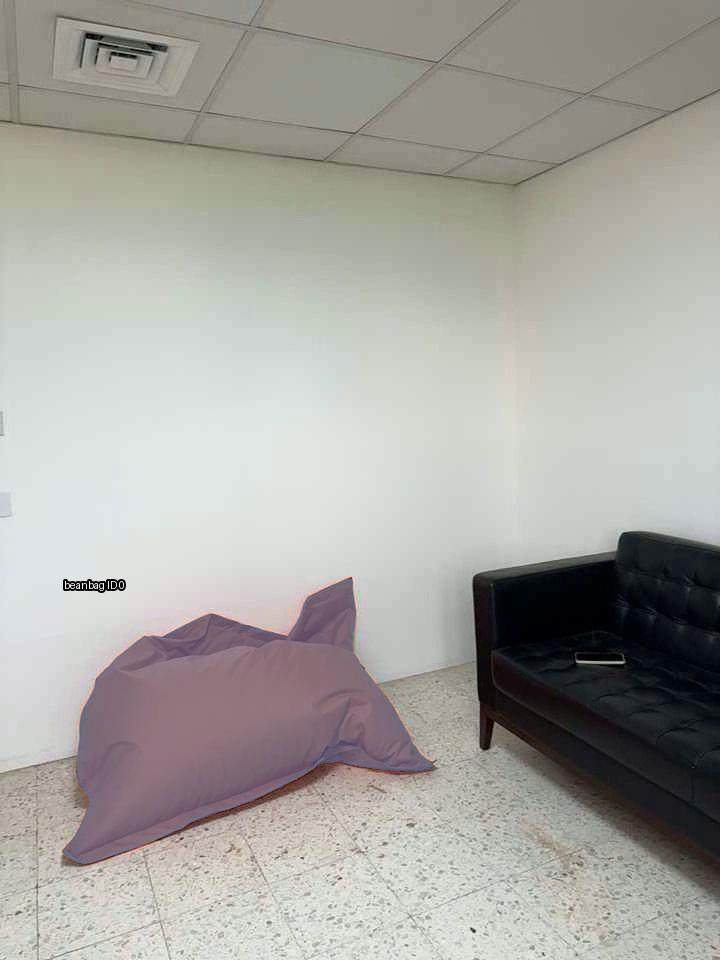

,class_name,region,valid_pixels,score,fraction_flagged,ego_refinement_supported
0,beanbag,box,2587,0.541639,0.000000,True
1,sofa,box,804,0.875534,0.000000,True
2,beanbag,sam3_refinement,2932,0.505034,0.000000,True
3,sofa,sam3_refinement,944,0.894012,0.007415,True
4,beanbag,sam31_tracking,2920,0.503244,0.000000,True
5,sofa,sam31_tracking,953,0.896545,0.007345,True
6,beanbag,box,2492,0.293490,0.000000,True
7,sofa,box,1646,0.530134,0.000000,True
8,beanbag,sam3_refinement,2632,0.256063,0.000000,True
9,sofa,sam3_refinement,2409,0.430097,0.000000,True


In [3]:
for prompt,filename in [('furniture','sam31_tracks.json'),('beanbag','sam31_beanbag_tracks.json')]:
    tracks=pd.DataFrame(json.loads((ROOT/'outputs/sam_trial'/filename).read_text()))
    assert set(tracks.frame)==set(range(400,490))
    assert (tracks.mask_pixels>0).all()
    display(tracks.groupby('object_id').agg(frames=('frame','nunique'),minimum_mask_pixels=('mask_pixels','min')))
display(Image(filename=str(ROOT/'outputs/sam_trial/sam31_beanbag_000450.jpg')))
motion=pd.read_csv(ROOT/'outputs/sam_trial/sam_motion_comparison.csv')
display(motion[['class_name','region','valid_pixels','score','fraction_flagged','ego_refinement_supported']])

class_name     accepted
air vent       True        17
armchair       True        23
beanbag        True        22
door           False       26
person         False        5
               True         1
picture        False        3
               True        32
sofa           False        1
               True        32
storage table  True        41
window         False       22
               True        18
dtype: int64

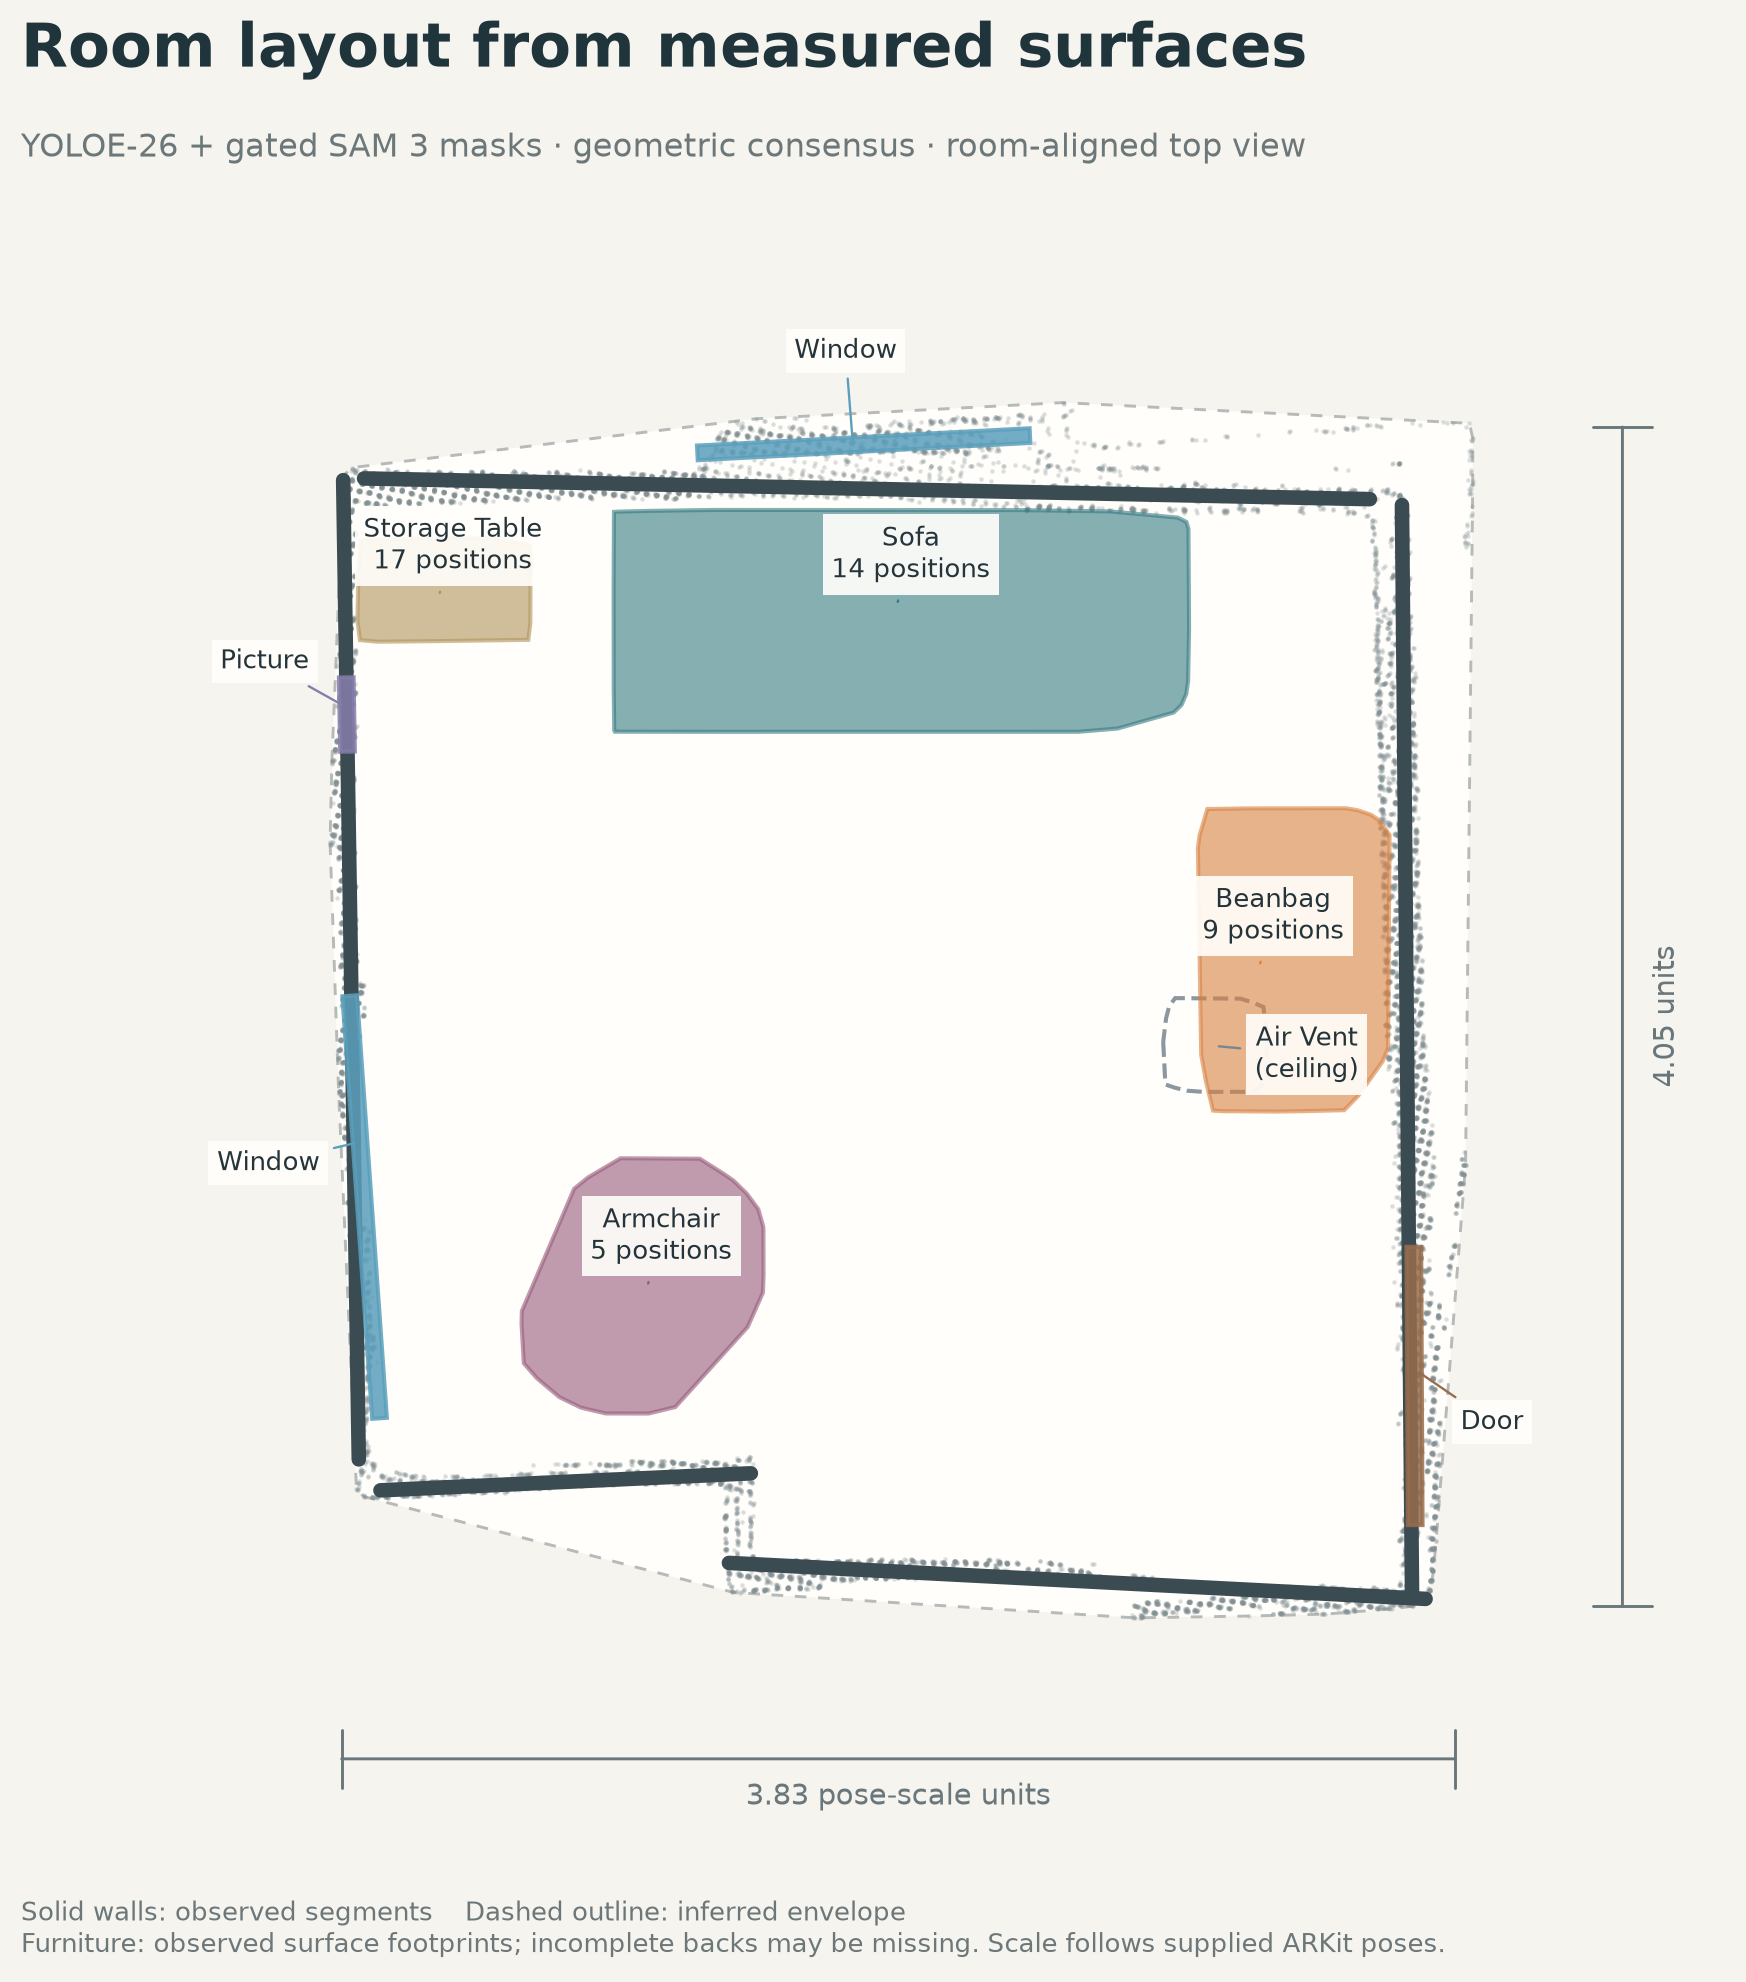

In [4]:
audit=pd.read_csv(ROOT/'outputs/sam_room/sam_fusion_audit.csv')
assert len(audit)==243 and audit.accepted.sum()==186
surfaces=np.load(ROOT/'outputs/sam_room/object_surfaces.npz')
assert np.isfinite(surfaces['points']).all()
objects=json.loads((ROOT/'outputs/sam_room/room_objects.json').read_text())
assert len(objects)==9
display(audit.groupby(['class_name','accepted']).size())
display(Image(filename=str(ROOT/'outputs/sam_room/room_floorplan.png')))

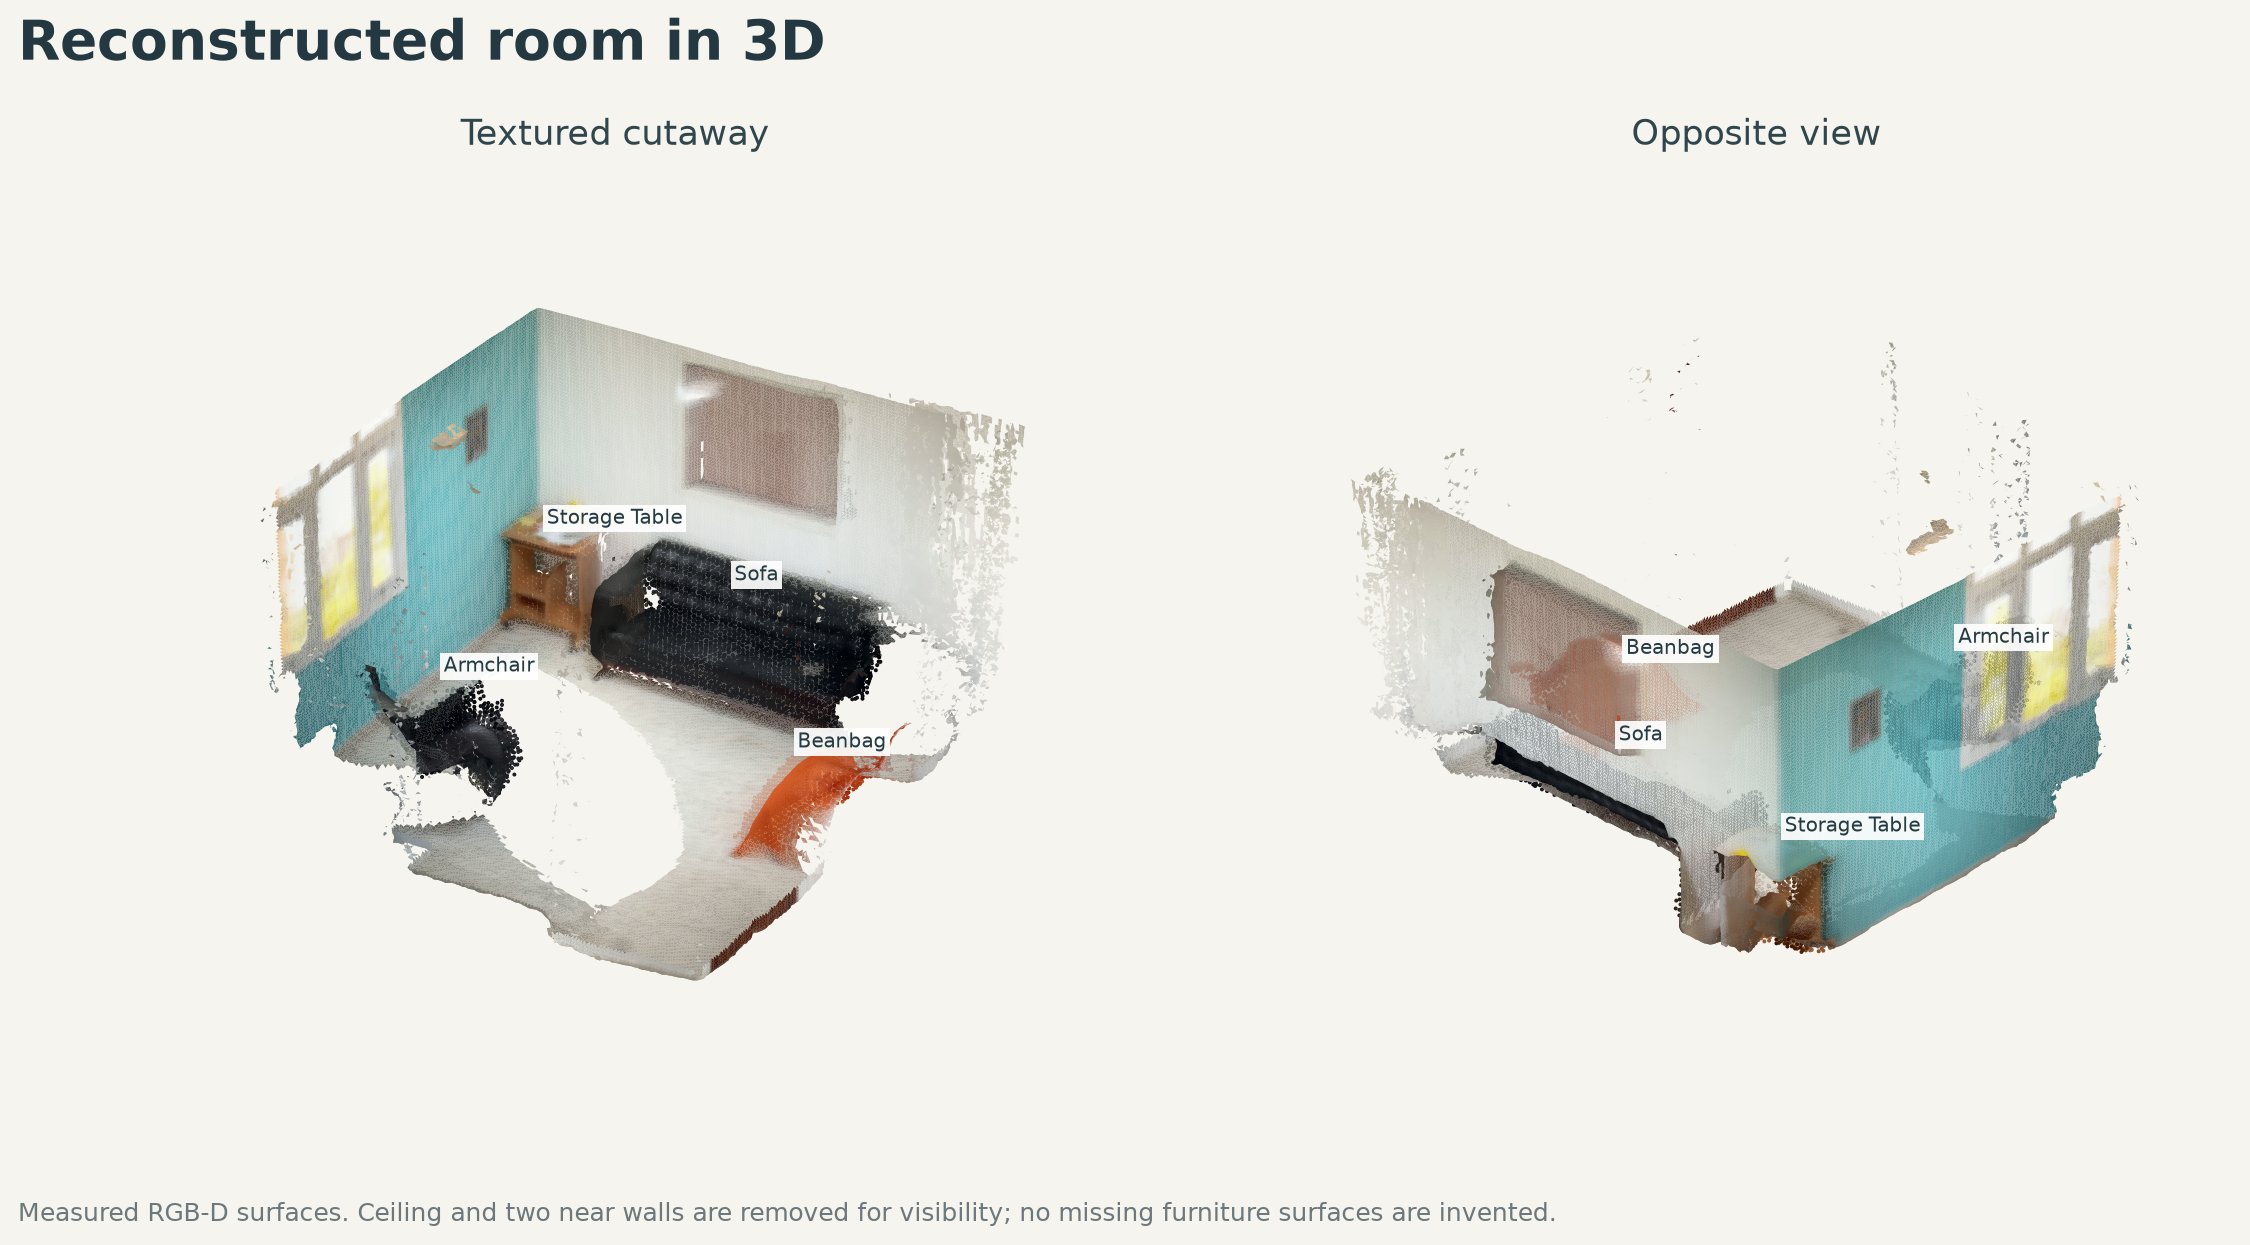

Measured mesh reused. Object surfaces refined; geometry holes and scale uncertainty remain.


In [5]:
display(Image(filename=str(ROOT/'outputs/sam_room/room_3d_cutaway.png')))
display(HTML('<a href="outputs/sam_room/room_3d_interactive.html" target="_blank">Open SAM-refined interactive 3D room</a>'))
print('Measured mesh reused. Object surfaces refined; geometry holes and scale uncertainty remain.')